# Experiment A — Final dataset-specific preprocessing evaluation

Compare untreated baseline and six active individual techniques on **250 IAM test lines and 250 Bentham test lines**, sampled without replacement with seed 5112. One pinned TrOCR checkpoint, fixed decoding and identical ordered test samples within each dataset. No training or combinations. Parts 2 and 3 are unchanged.

Select each technique's parameters separately for IAM and Bentham using only the completed validation summaries: lowest active-configuration CER, then WER; exact ties retain the original prespecified grid order. The setup table records every selection and parameter. IAM: denoising h=7; deskew max_angle=5°, step=0.5° (tied with 10° and 15°); CLAHE clip=1, grid=8x8. Bentham: denoising h=1; deskew max_angle=10°, step=0.25°; CLAHE clip=2, grid=16x16. Both: size height=128, standard grayscale and global min-max intensity normalization.

Baseline remains a separate control even when it outperformed an active technique in validation. This measures the effect of applying each technique; it does not replace unsuccessful techniques with baseline. Frozen configurations and validation provenance are recorded before test inference. The initial shared-parameter run was interrupted after the user clarified dataset-specific selection; its artifacts are retained separately. No parameter was chosen from test scores.

This is final evaluation on fixed test subsets, not the complete partitions. Do not tune from these results. Corpus CER/WER collapse whitespace and retain case/punctuation. Mandatory model RGB conversion, resizing and normalization follow optional preprocessing. Bentham RGBA is composited over white equally for baseline and treatments. Originals remain unchanged. IAM is within TrOCR's training domain; Bentham is historical handwriting. Saved split provenance does not establish absence of overlap with pretrained training data.

In [1]:
from pathlib import Path
import sys
import json
import platform
import hashlib
import random
from datetime import datetime, timezone
from importlib.metadata import version

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/load_dataset/iam.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.models import TrOCRRecognizer
from src.preprocessing import (PreprocessingPipeline, Grayscale, NonLocalMeans,
    Deskew, CLAHE, IntensityNormalization, SizeNormalization)
from src.validation.denoising import adapt_image, evaluate
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [7]:
from importlib import import_module
from src.evaluation.selection import select_validation_configuration
SPLIT = "test"
SAMPLE_COUNT = 250
SEED = 5112
BATCH_SIZE = 8
STUDIES = {
    "denoising": "denoising/20261112T000633091905Z",
    "deskew": "deskew/20261112T002245100371Z",
    "clahe": "clahe/20261112T003254359727Z",
    "grayscale": "grayscale/20261112T004235992760Z",
    "intensity_normalization": "intensity_normalization/20261112T010446875353Z",
    "size_normalization": "size_normalization/20261112T010953112528Z",
}
reference = json.loads((ROOT / "results/validation" / STUDIES["denoising"] / "metadata.json").read_text())
DATASET_REVISION = reference["iam_revision"]
CHECKPOINT = reference["model"]["checkpoint"]
MODEL_REVISION = reference["model"]["revision"]
DEVICE = reference["model"]["device"]
GENERATION = reference["model"]["generation_kwargs"]
pipeline_names = ["baseline", "grayscale", "denoising", "deskew", "clahe", "intensity_normalization", "size_normalization"]
pipelines_by_dataset, selections, selection_rows = {}, {}, []
for dataset_name in ("iam", "bentham"):
    pipelines_by_dataset[dataset_name] = {"baseline": PreprocessingPipeline()}
    selections[dataset_name] = {}
    for technique in pipeline_names[1:]:
        folder = ROOT / "results/validation" / STUDIES[technique]
        scores = pd.read_csv(folder / "comparison.csv", converters={"cer": float, "wer": float})
        chosen = select_validation_configuration(scores, dataset_name)
        registry = import_module("src.validation." + technique).configurations()
        step = registry[chosen["configuration"]]
        validation_metadata = json.loads((folder / "metadata.json").read_text())
        assert validation_metadata["split"] == "validation"
        assert json.loads(json.dumps(step.to_config())) == validation_metadata["configurations"][chosen["configuration"]]
        pipelines_by_dataset[dataset_name][technique] = PreprocessingPipeline((step,))
        selections[dataset_name][technique] = chosen
        selection_rows.append({"dataset": dataset_name, "technique": technique,
            "validation_configuration": chosen["configuration"], "validation_cer": chosen["cer"],
            "validation_wer": chosen["wer"], "parameters": json.dumps(step.to_config())})
assert SPLIT == "test" and SAMPLE_COUNT == 250 and REVISION == reference["bentham_revision"]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
frozen_config = {dataset_name: {name: pipe.to_config() for name, pipe in pipes.items()}
                 for dataset_name, pipes in pipelines_by_dataset.items()}
config_digest = hashlib.sha256(json.dumps(frozen_config, sort_keys=True).encode()).hexdigest()
selection_table = pd.DataFrame(selection_rows)
print("Dataset-specific selections: lowest active validation CER, then WER; exact ties retain original grid order.")
display(selection_table)
print("Frozen configuration SHA-256:", config_digest)

Dataset-specific selections: lowest active validation CER, then WER; exact ties retain original grid order.


,dataset,technique,validation_configuration,validation_cer,validation_wer,parameters
0,iam,grayscale,grayscale,0.011541,0.043803,"{""name"": ""grayscale"", ""enabled"": true, ""output..."
1,iam,denoising,nlm_h7,0.010862,0.040598,"{""name"": ""non_local_means"", ""enabled"": true, ""..."
2,iam,deskew,deskew_max5_step0.5,0.011767,0.041667,"{""name"": ""deskew"", ""enabled"": true, ""max_angle..."
3,iam,clahe,clahe_clip1_grid8x8,0.013804,0.045940,"{""name"": ""clahe"", ""enabled"": true, ""clip_limit..."
4,iam,intensity_normalization,intensity_normalization,0.011994,0.045940,"{""name"": ""intensity_normalization"", ""enabled"":..."
5,iam,size_normalization,size_height128,0.011541,0.043803,"{""name"": ""size_normalization"", ""enabled"": true..."
6,bentham,grayscale,grayscale,0.159639,0.295480,"{""name"": ""grayscale"", ""enabled"": true, ""output..."
7,bentham,denoising,nlm_h1,0.154679,0.293275,"{""name"": ""non_local_means"", ""enabled"": true, ""..."
8,bentham,deskew,deskew_max10_step0.25,0.156032,0.299890,"{""name"": ""deskew"", ""enabled"": true, ""max_angle..."
9,bentham,clahe,clahe_clip2_grid16x16,0.146336,0.291069,"{""name"": ""clahe"", ""enabled"": true, ""clip_limit..."


Frozen configuration SHA-256: ed3864f2f81287422af34e216fd234efdc4ba85c88ee3da86d9883830f4c5e6e


In [3]:
datasets = {
    "iam": load_iam_dataset(split=SPLIT, revision=DATASET_REVISION),
    "bentham": load_bentham_dataset(split=SPLIT),
}
selected, indices_by_dataset, samples_by_dataset, sample_rows = {}, {}, {}, []
for dataset_name, dataset in datasets.items():
    assert {"image", "text"}.issubset(dataset.column_names)
    assert len(dataset) >= SAMPLE_COUNT
    indices = sorted(np.random.default_rng(SEED).choice(len(dataset), SAMPLE_COUNT, replace=False).tolist())
    indices_by_dataset[dataset_name] = indices
    subset = dataset.select(indices)
    if dataset_name == "iam":
        subset = subset.add_column("id", [f"sample_{i}" for i in indices])
    selected[dataset_name] = subset
    samples = []
    for index, row in zip(indices, subset):
        assert isinstance(row["text"], str) and row["text"].strip()
        image = adapt_image(row["image"])
        sample = {"id": row["id"], "image": image, "ground_truth": row["text"]}
        samples.append(sample)
        sample_rows.append({"dataset": dataset_name, "sample_id": sample["id"],
            "dataset_index": index, "source_mode": row["image"].mode,
            "mode": image.mode, "width": image.width, "height": image.height,
            "ground_truth": row["text"]})
    assert len({s["id"] for s in samples}) == SAMPLE_COUNT
    samples_by_dataset[dataset_name] = samples
sample_info = pd.DataFrame(sample_rows)
print("Test split sizes:", {name: len(ds) for name, ds in datasets.items()})
display(sample_info.groupby(["dataset", "source_mode", "mode"]).size().rename("selected_lines").to_frame())
display(sample_info.groupby("dataset").head(2))

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Flattening the indices:   0%|          | 0/250 [00:00<?, ? examples/s]

Test split sizes: {'iam': 2915, 'bentham': 860}


,,,selected_lines
dataset,source_mode,mode,
bentham,RGBA,RGB,250
iam,L,L,250


,dataset,sample_id,dataset_index,source_mode,mode,width,height,ground_truth
0,iam,sample_11,11,L,L,959,128,round a doll's house .
1,iam,sample_18,18,L,L,2209,128,such as a chair and a motor-car . The idea is ...
250,bentham,096_028_001_01_03,2,RGBA,RGB,1573,154,in paving the way to the consideration of
251,bentham,096_028_001_01_06,5,RGBA,RGB,1607,145,much time in explaining the nature &


## Final inference and saved artifacts

Load TrOCR once and warm up before recording timings. Run each frozen configuration on both fixed test subsets. Save configuration/selection provenance and sample manifests before inference, then checkpoint predictions after every batch. Results are under results/test/experiment_a/<UTC run ID>/<dataset>/<configuration>/.

Timings include mandatory processor transforms and generation; optional preprocessing is separate. Model loading and warm-up are excluded. This sequential run is not a controlled speed benchmark. If interrupted within this kernel, rerun only the inference cell to resume. Do not rerun setup to choose another test sample or alter parameters.

In [6]:
# Create once per kernel session so rerunning this cell resumes saved batches.
if "run_dir" not in globals() or json.loads((run_dir / "metadata.json").read_text()).get("frozen_configuration_sha256") != config_digest:
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    run_dir = ROOT / "results/test/experiment_a" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    metadata = {
        "experiment_id": run_id, "phase": "final_test", "split": SPLIT,
        "sample_count_per_dataset": SAMPLE_COUNT, "seed": SEED,
        "sampling": "numpy default_rng seeded without replacement; sorted source indices per dataset",
        "sample_indices": indices_by_dataset, "frozen_configuration_sha256": config_digest,
        "preprocessing": frozen_config, "selection_studies": STUDIES, "validation_selections": selections,
        "selection_rule": "per-dataset lowest active validation CER; WER tie-breaker; exact ties use grid order",
        "datasets": {name: {"split_size": len(ds), "fingerprint": ds._fingerprint,
            "selected_fingerprint": selected[name]._fingerprint,
            "revision": DATASET_REVISION if name == "iam" else REVISION}
            for name, ds in datasets.items()},
        "bentham_archive_sha256": ARCHIVES,
        "normalization": "collapse whitespace; retain case and punctuation",
        "input_adaptation": "RGBA white composite; preserve L/RGB",
        "python": platform.python_version(), "platform": platform.platform(),
        "versions": {p: version(p) for p in ("torch", "transformers", "datasets",
            "huggingface-hub", "jiwer", "numpy", "Pillow", "opencv-python-headless", "pandas", "matplotlib")},
    }
    sample_info.to_csv(run_dir / "samples.csv", index=False)
    selection_table.to_csv(run_dir / "validation_parameter_selections.csv", index=False)
    (run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
    (run_dir / "status.json").write_text(json.dumps({"status": "running", "expected_dataset_configuration_pairs": 14}))
saved_protocol = json.loads((run_dir / "metadata.json").read_text())
assert saved_protocol["frozen_configuration_sha256"] == config_digest
assert saved_protocol["sample_indices"] == indices_by_dataset
assert saved_protocol["split"] == "test" and saved_protocol["sample_count_per_dataset"] == 250
if "model" not in globals() or model.revision != MODEL_REVISION or str(model.device) != DEVICE:
    model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION,
                           device=DEVICE, generation_kwargs=GENERATION)
    _ = model.predict(samples_by_dataset["iam"][0]["image"])
metadata["model"] = model.to_config()
(run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
assert config_digest == hashlib.sha256(json.dumps({dataset_name: {name: p.to_config() for name, p in pipes.items()} for dataset_name, pipes in pipelines_by_dataset.items()}, sort_keys=True).encode()).hexdigest()
summaries = []
for name in pipeline_names:
    for dataset_name, dataset in selected.items():
        pipeline = pipelines_by_dataset[dataset_name][name]
        # Reuse only matching baseline/grayscale checkpoints from the interrupted run.
        # The shared evaluator also verifies the full signed identity before reuse.
        import shutil
        previous_run = ROOT / "results/test/experiment_a/20261112T023508667178Z"
        previous_folder = previous_run / dataset_name / name
        current_folder = run_dir / dataset_name / name
        if name in ("baseline", "grayscale") and previous_folder.exists() and not current_folder.exists():
            old_protocol = json.loads((previous_run / "metadata.json").read_text())
            identity = json.loads((previous_folder / "identity.json").read_text())
            assert old_protocol["sample_indices"] == indices_by_dataset
            assert identity["dataset_fingerprint"] == dataset._fingerprint
            assert identity["transform"] == pipeline.to_config()
            assert identity["model"] == json.loads(json.dumps(model.to_config()))
            shutil.copytree(previous_folder, current_folder)
            metadata.setdefault("reused_prediction_sources", {})[dataset_name + "/" + name] = str(previous_folder.relative_to(ROOT))
            (run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
        result = evaluate(dataset, dataset_name, model, name, pipeline, run_dir, BATCH_SIZE)
        summaries.append(result)
        pd.DataFrame(summaries).to_csv(run_dir / "partial_summary.csv", index=False)
        print(result, flush=True)
summary = pd.DataFrame(summaries)
assert len(summary) == 14 and summary.sample_count.eq(SAMPLE_COUNT).all()
for metric in ("cer", "wer"):
    base = summary[summary.configuration == "baseline"].set_index("dataset")[metric]
    summary[f"{metric}_change_pp"] = 100 * (summary[metric] - summary.dataset.map(base))
    summary[f"{metric}_relative_change_pct"] = 100 * (summary[metric] / summary.dataset.map(base) - 1)
summary["total_seconds"] = summary.preprocessing_seconds + summary.inference_seconds
summary["seconds_per_line"] = summary.total_seconds / summary.sample_count
frames = []
for dataset_name in selected:
    for name in pipeline_names:
        frame = pd.read_csv(run_dir / dataset_name / name / "predictions.csv", keep_default_na=False)
        assert frame.sample_id.tolist() == [s["id"] for s in samples_by_dataset[dataset_name]]
        frames.append(frame.assign(dataset=dataset_name, configuration=name))
predictions = pd.concat(frames, ignore_index=True)
summary.to_csv(run_dir / "summary.csv", index=False)
predictions.to_csv(run_dir / "predictions.csv", index=False)
(run_dir / "status.json").write_text(json.dumps({"status": "inference_complete", "completed_dataset_configuration_pairs": 14}))
print("Saved final test results:", run_dir)
display(summary)

{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 250, 'cer': 0.04776260009420631, 'wer': 0.10812023328847016, 'preprocessing_seconds': 0.007902452001872007, 'inference_seconds': 75.54761058299846}
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 250, 'cer': 0.16121244635193133, 'wer': 0.428854734754586, 'preprocessing_seconds': 0.09649438100677799, 'inference_seconds': 70.62097046100462}
{'dataset': 'iam', 'configuration': 'grayscale', 'sample_count': 250, 'cer': 0.04776260009420631, 'wer': 0.10812023328847016, 'preprocessing_seconds': 0.01089266400958877, 'inference_seconds': 72.02086433300065}
bentham/grayscale: 80/250
bentham/grayscale: 160/250
bentham/grayscale: 240/250
bentham/grayscale: 250/250
{'dataset': 'bentham', 'configuration': 'grayscale', 'sample_count': 250, 'cer': 0.16121244635193133, 'wer': 0.428854734754586, 'preprocessing_seconds': 0.1117807169957814, 'inference_seconds': 70.39445291399898}
iam/denoising: 8/250
iam/denoising: 80/250


,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_change_pp,cer_relative_change_pct,wer_change_pp,wer_relative_change_pct,total_seconds,seconds_per_line
0,iam,baseline,250,0.047763,0.108120,0.007902,75.547611,0.000000,0.000000,0.000000,0.000000,75.555513,0.302222
1,bentham,baseline,250,0.161212,0.428855,0.096494,70.620970,0.000000,0.000000,0.000000,0.000000,70.717465,0.282870
2,iam,grayscale,250,0.047763,0.108120,0.010893,72.020864,0.000000,0.000000,0.000000,0.000000,72.031757,0.288127
3,bentham,grayscale,250,0.161212,0.428855,0.111781,70.394453,0.000000,0.000000,0.000000,0.000000,70.506234,0.282025
4,iam,denoising,250,0.046161,0.104980,16.191690,72.914041,-0.160151,-3.353057,-0.314042,-2.904564,89.105732,0.356423
5,bentham,denoising,250,0.162375,0.425384,34.433061,72.211703,0.116237,0.721021,-0.347050,-0.809249,106.644764,0.426579
6,iam,deskew,250,0.047668,0.107672,2.889562,71.972542,-0.009421,-0.197239,-0.044863,-0.414938,74.862104,0.299448
7,bentham,deskew,250,0.169617,0.438275,11.714894,70.370088,0.840486,5.213533,0.941993,2.196532,82.084982,0.328340
8,iam,clahe,250,0.046538,0.108569,0.079976,73.023635,-0.122468,-2.564103,0.044863,0.414938,73.103611,0.292414
9,bentham,clahe,250,0.147353,0.407536,0.357779,70.633305,-1.385908,-8.596783,-2.131879,-4.971098,70.991084,0.283964


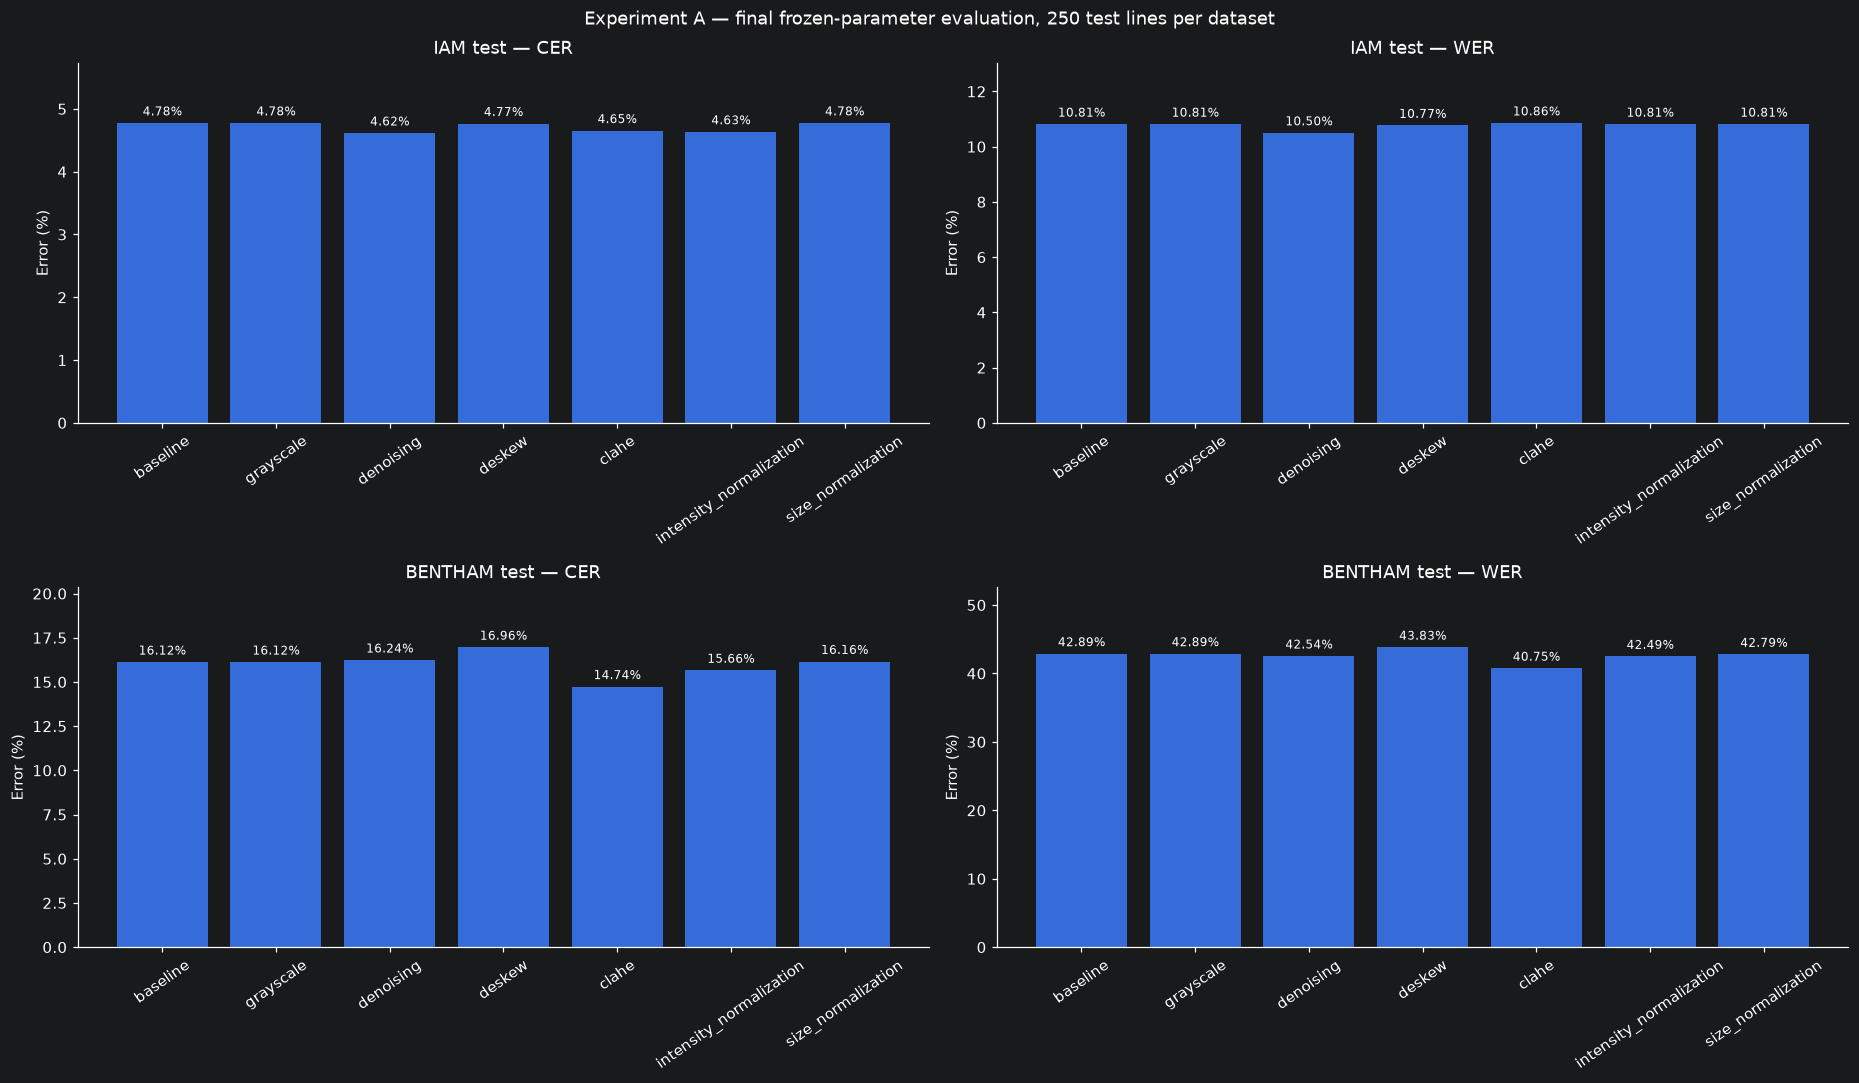

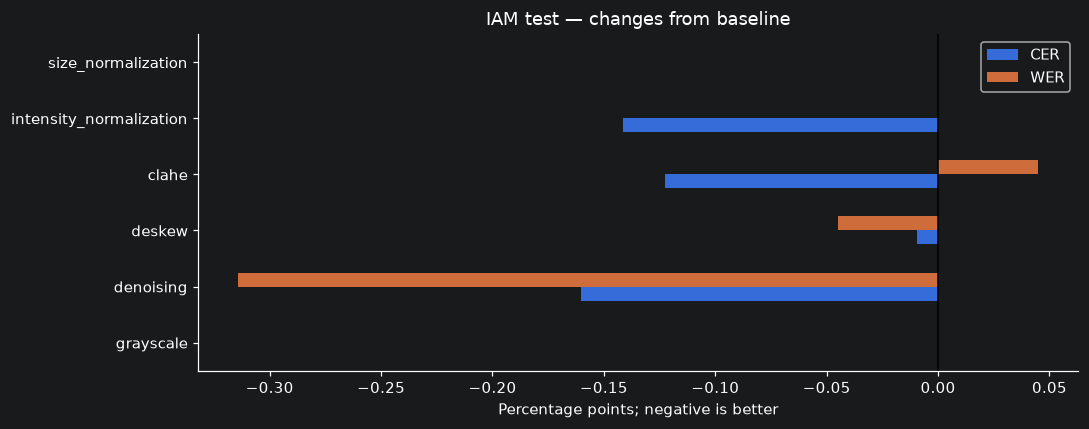

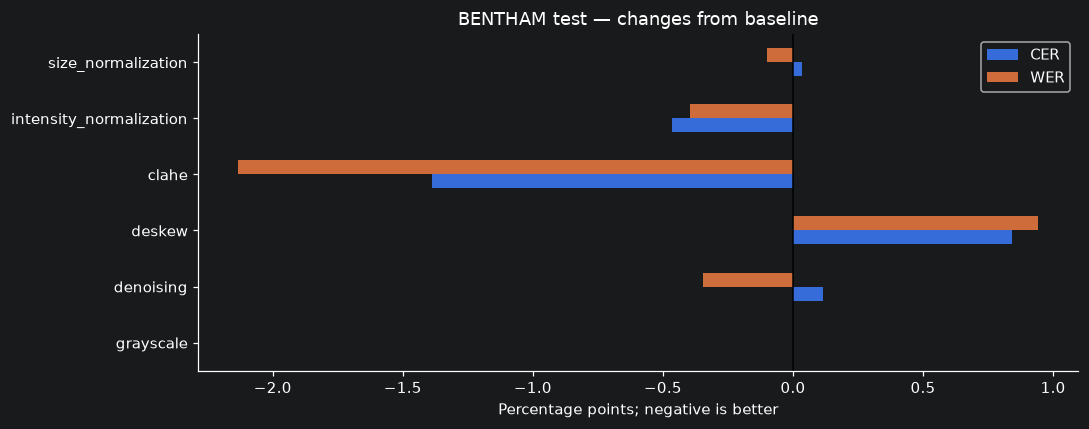

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(17, 10))
for row, dataset_name in enumerate(selected):
    current = summary[summary.dataset == dataset_name].set_index("configuration").loc[pipeline_names]
    for col, metric in enumerate(("cer", "wer")):
        values = 100 * current[metric]
        bars = axes[row, col].bar(current.index, values)
        axes[row, col].bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=3, fontsize=8)
        axes[row, col].set(title=f"{dataset_name.upper()} test — {metric.upper()}", ylabel="Error (%)")
        axes[row, col].tick_params(axis="x", rotation=35)
        axes[row, col].margins(y=.2)
fig.suptitle("Experiment A — final frozen-parameter evaluation, 250 test lines per dataset")
fig.tight_layout()
fig.savefig(run_dir / "corpus_error_rates.png", bbox_inches="tight")
plt.show()
for dataset_name in selected:
    current = summary[summary.dataset == dataset_name].set_index("configuration").drop(index="baseline")
    ax = current[["cer_change_pp", "wer_change_pp"]].rename(columns={"cer_change_pp":"CER", "wer_change_pp":"WER"}).plot.barh(figsize=(10, 4))
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=f"{dataset_name.upper()} test — changes from baseline", xlabel="Percentage points; negative is better", ylabel="")
    plt.tight_layout()
    plt.savefig(run_dir / f"{dataset_name}_corpus_changes.png", bbox_inches="tight")
    plt.show()

## Where does preprocessing help or hurt?

The next plots pair each line with its own baseline. The scatter diagonal means equal CER. The count chart uses per-line CER to count improved, unchanged, and worsened lines; these counts are diagnostics, not corpus metrics or a statistical significance test. A technique can help many short lines and still worsen corpus CER if it damages longer lines.

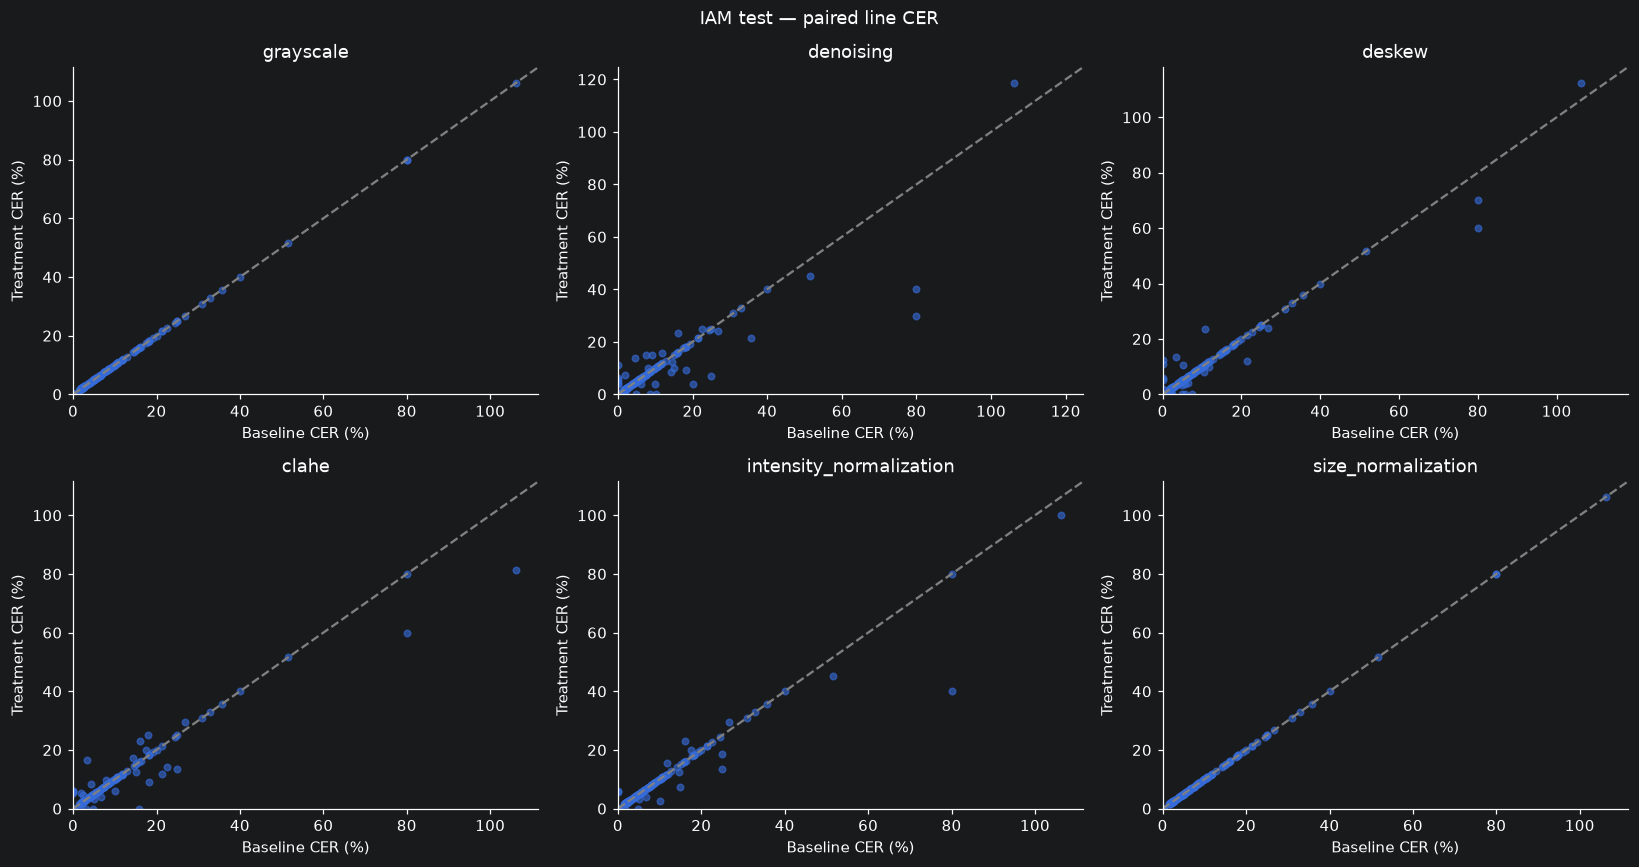

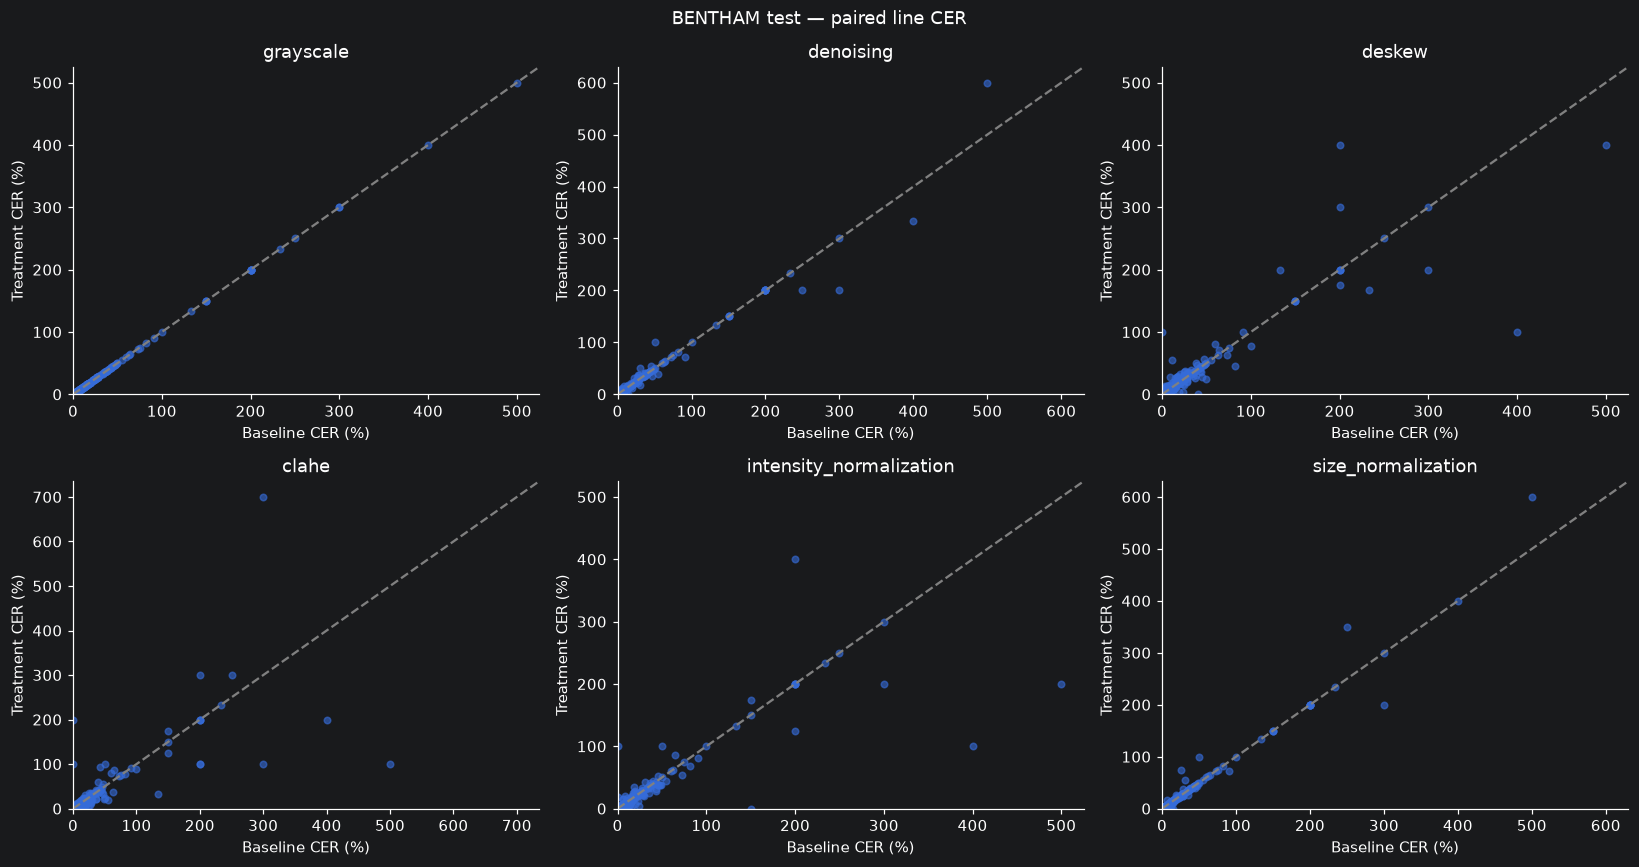

,dataset,configuration,Improved,Unchanged,Worsened
0,iam,grayscale,0,250,0
1,iam,denoising,17,219,14
2,iam,deskew,14,227,9
3,iam,clahe,14,223,13
4,iam,intensity_normalization,12,232,6
5,iam,size_normalization,0,250,0
6,bentham,grayscale,0,250,0
7,bentham,denoising,20,205,25
8,bentham,deskew,44,140,66
9,bentham,clahe,82,117,51


In [9]:
treatments = [name for name in pipeline_names if name != "baseline"]
paired_by_dataset = {}
outcome_rows = []
for dataset_name in selected:
    paired = predictions[predictions.dataset == dataset_name].pivot(index="sample_id", columns="configuration", values="cer")
    paired_by_dataset[dataset_name] = paired
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, name in zip(axes.flat, treatments):
        x, y = 100 * paired["baseline"], 100 * paired[name]
        limit = max(float(x.max()), float(y.max()), 1) * 1.05
        ax.scatter(x, y, alpha=.6, s=18)
        ax.plot([0, limit], [0, limit], "--", color="gray")
        ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Baseline CER (%)", ylabel="Treatment CER (%)", title=name)
        delta = paired[name] - paired["baseline"]
        same = np.isclose(delta, 0, atol=1e-12, rtol=0)
        outcome_rows.append({"dataset": dataset_name, "configuration": name,
            "Improved": int(((delta < 0) & ~same).sum()), "Unchanged": int(same.sum()),
            "Worsened": int(((delta > 0) & ~same).sum())})
    fig.suptitle(f"{dataset_name.upper()} test — paired line CER")
    fig.tight_layout()
    fig.savefig(run_dir / f"{dataset_name}_paired_line_cer.png", bbox_inches="tight")
    plt.show()
outcomes = pd.DataFrame(outcome_rows)
outcomes.to_csv(run_dir / "line_outcomes.csv", index=False)
display(outcomes)

iam/grayscale/sample_1014
Reference: In China , for instance , dried rats are esteemed
Baseline: In China , for instance , dried rats are esteemed
Treatment: In China , for instance , dried rats are esteemed


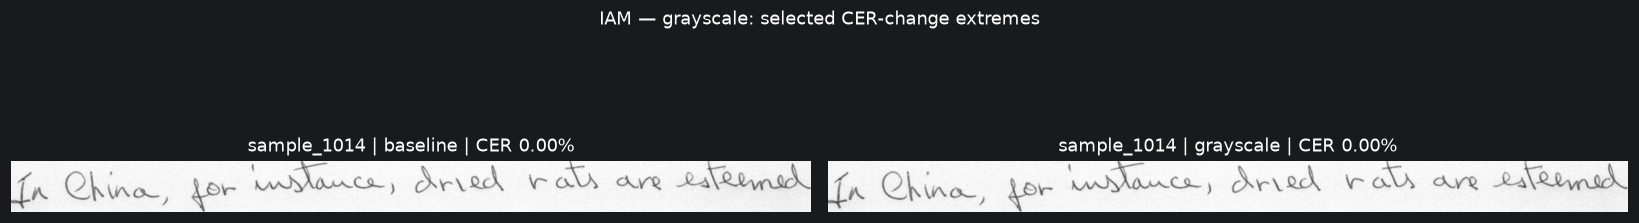

iam/denoising/sample_798
Reference: darkness .
Baseline: at a business .
Treatment: dazzeness .
iam/denoising/sample_1669
Reference: trans-economic .
Baseline: transuming a recession in C.
Treatment: Lhasing in accessions i.c.


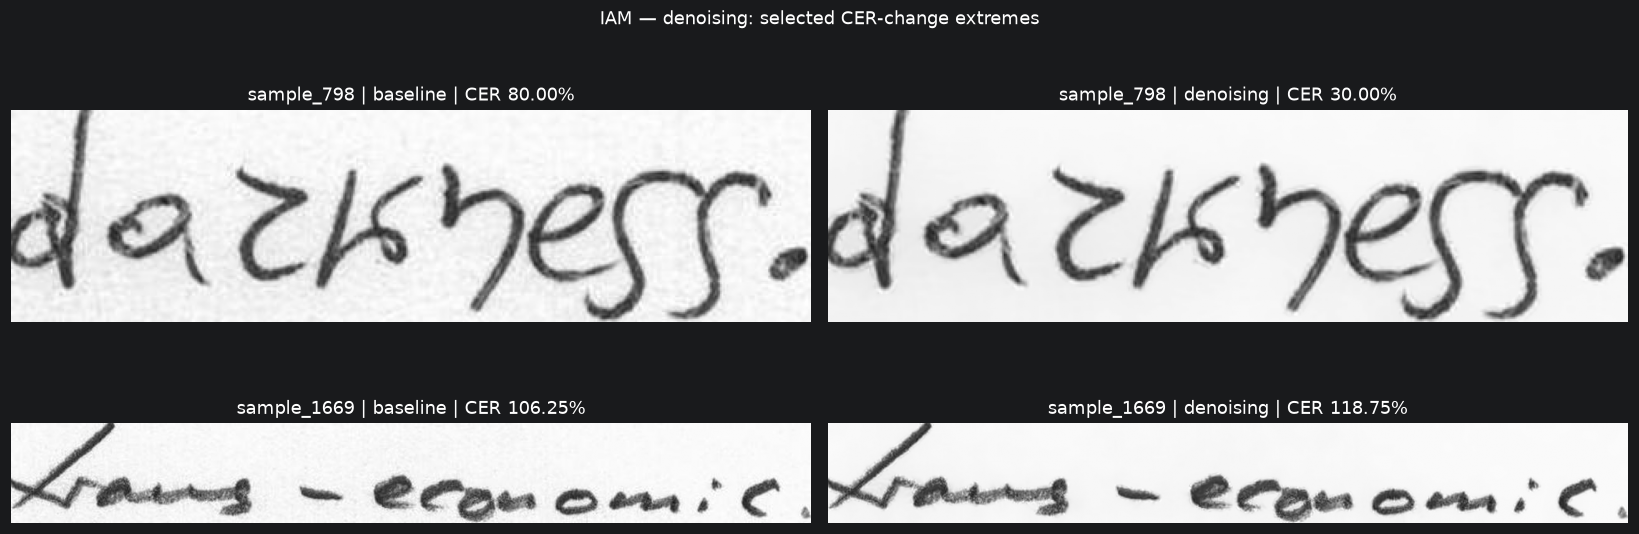

iam/deskew/sample_2505
Reference: in pairs .
Baseline: an inquiry
Treatment: an inquiry .
iam/deskew/sample_141
Reference: supply . The pools are probably natural springs
Baseline: supply . The pads and probably natural springs
Treatment: supply . The pads once probably nullival springs


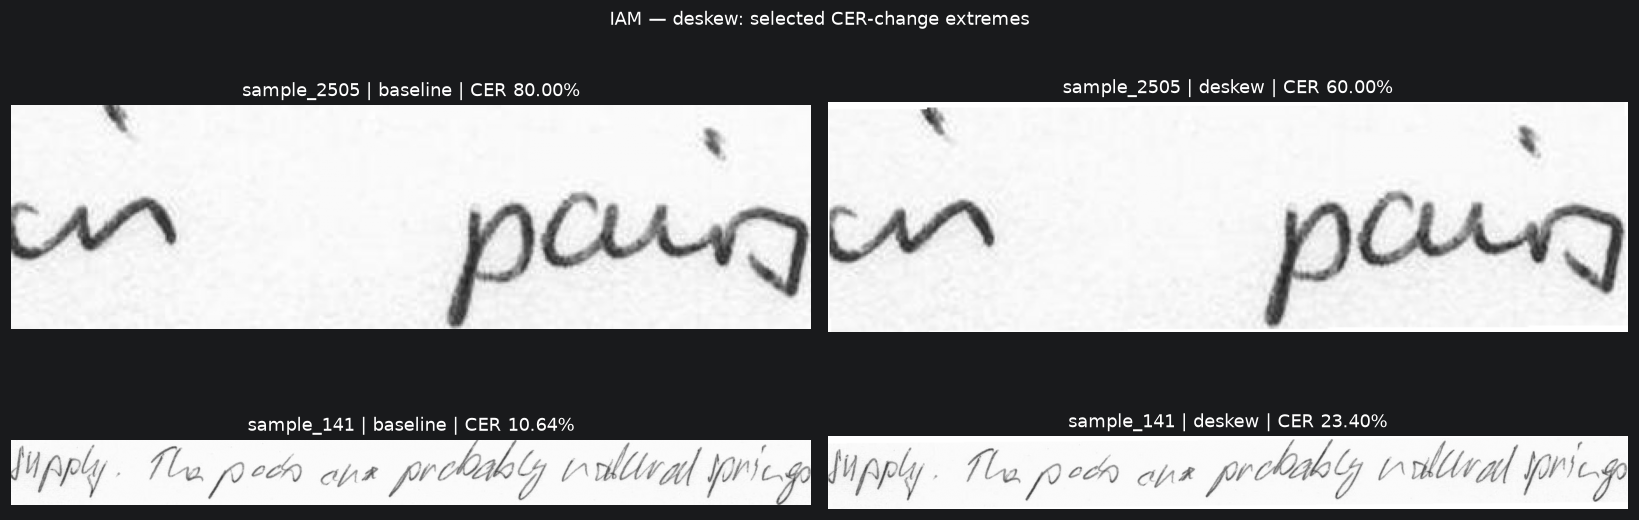

iam/clahe/sample_1669
Reference: trans-economic .
Baseline: transuming a recession in C.
Treatment: transume in economic music .
iam/clahe/sample_638
Reference: movements , although primarily
Baseline: Movements , although primarily
Treatment: Moeemunk , although primarily


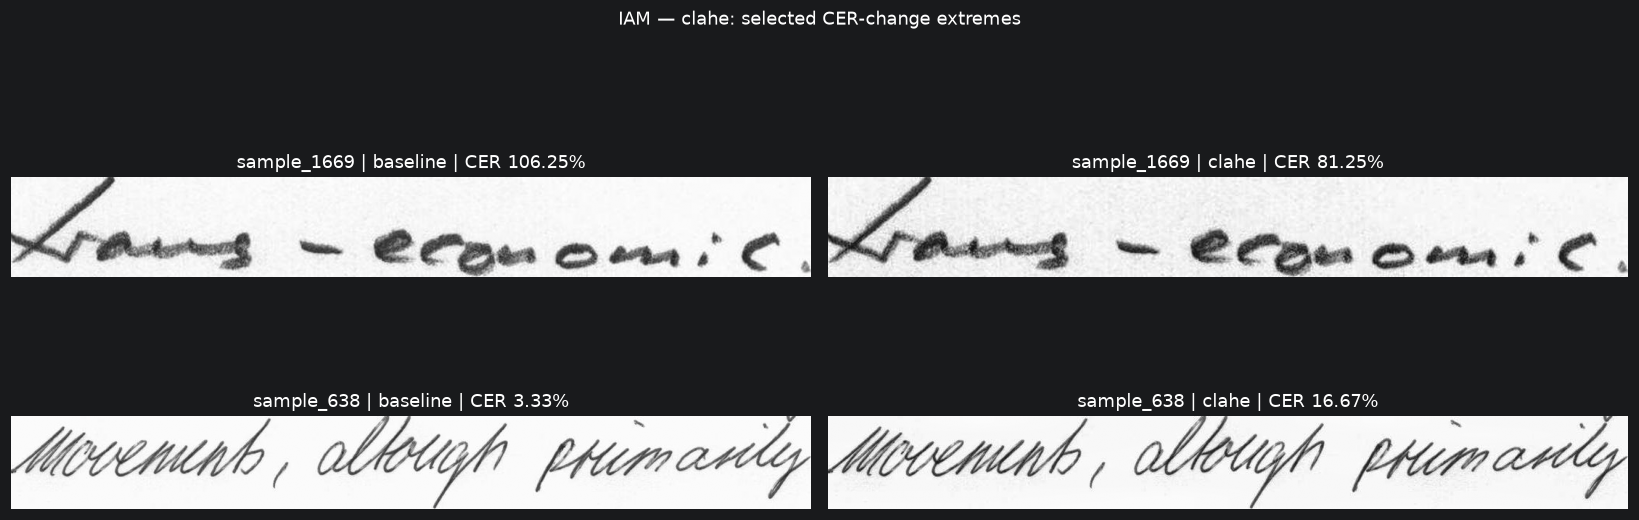

iam/intensity_normalization/sample_2505
Reference: in pairs .
Baseline: an inquiry
Treatment: cin pains
iam/intensity_normalization/sample_2056
Reference: express their disgust at Sir John's abominable treatment
Baseline: express their biggest # at Sir. John's admirable treatment
Treatment: ex per their biggest # at Sir. John's admirable treatment


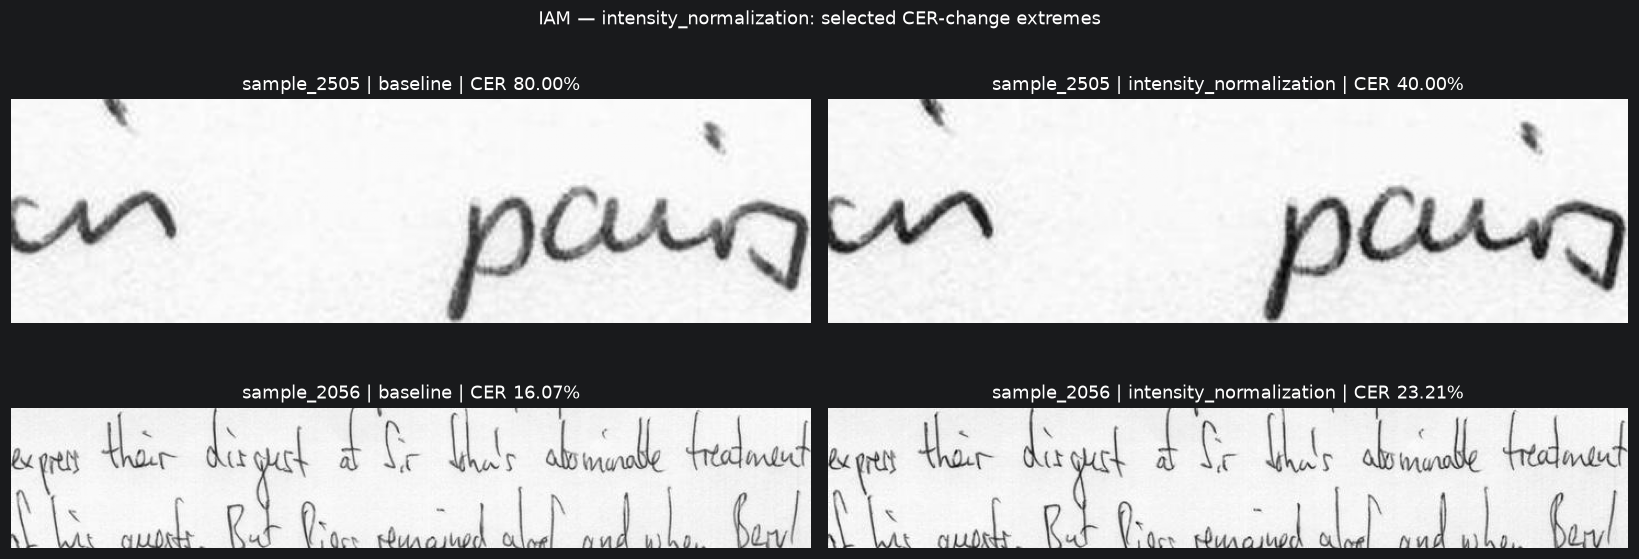

iam/size_normalization/sample_1014
Reference: In China , for instance , dried rats are esteemed
Baseline: In China , for instance , dried rats are esteemed
Treatment: In China , for instance , dried rats are esteemed


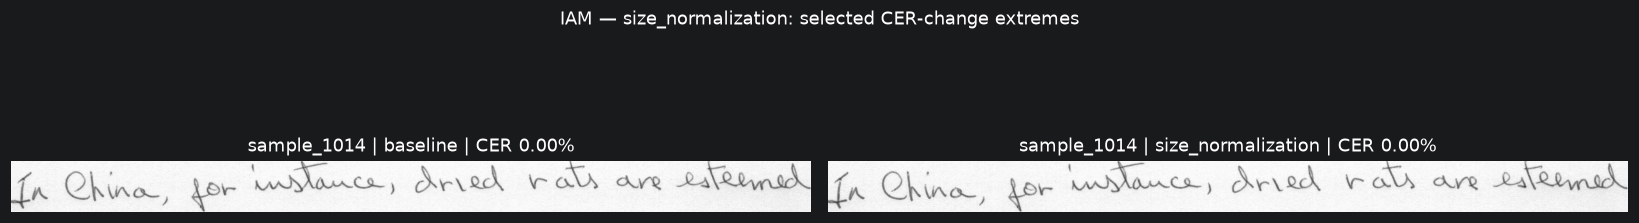

bentham/grayscale/002_579_001_02_07
Reference: way as that in question in the former case as in the latter. 
Baseline: way as that in question is the former case as in the letter .
Treatment: way as that in question is the former case as in the letter .


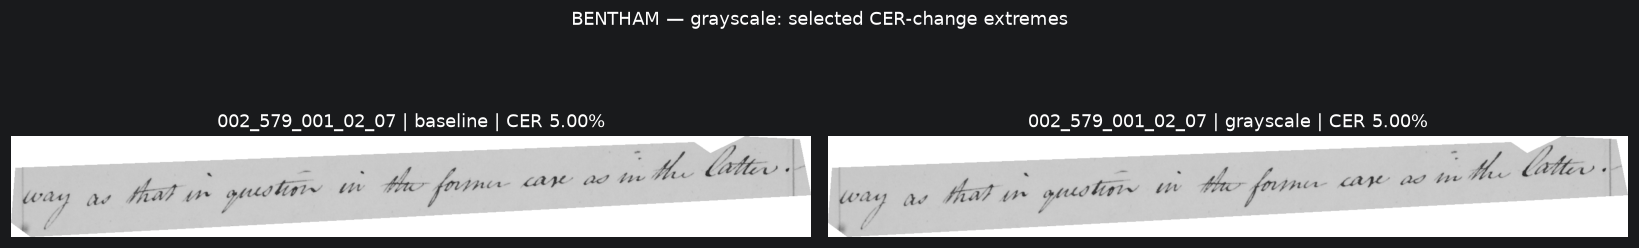

bentham/denoising/073_083_001_03_19
Reference: e 
Baseline: 2 .
Treatment: 2.
bentham/denoising/115_077_002_01_01
Reference: 9 
Baseline: ailey
Treatment: relief


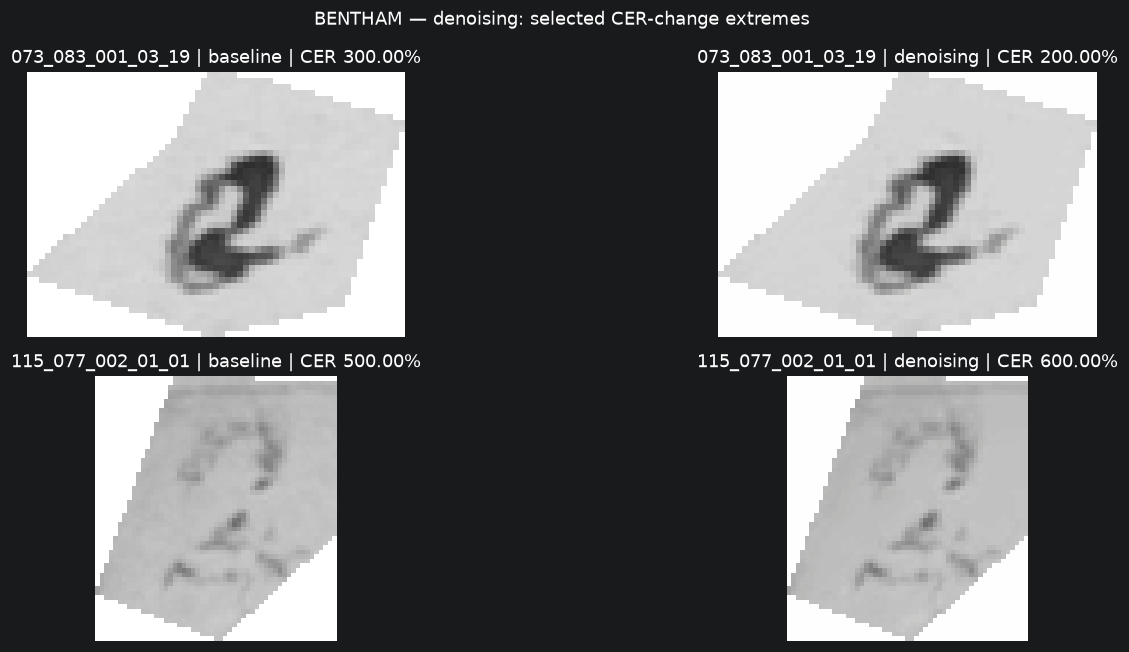

bentham/deskew/071_030_001_04_24
Reference: III 
Baseline: clack back .
Treatment: all
bentham/deskew/071_108_002_02_01
Reference: C 
Baseline: ci
Treatment: c.i.


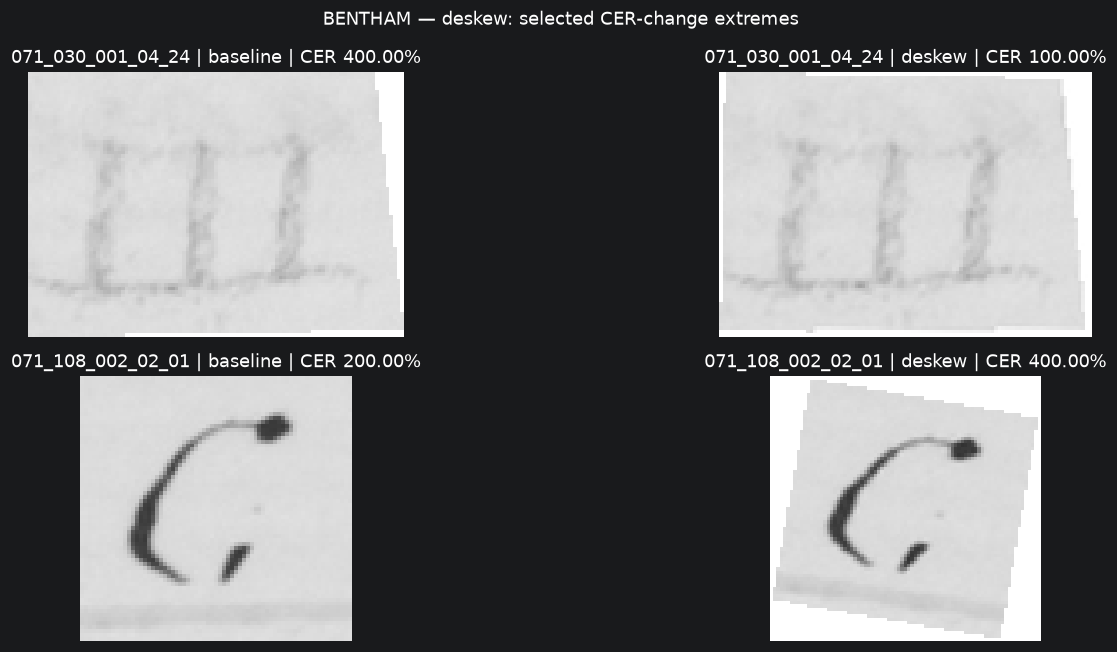

bentham/clahe/115_077_002_01_01
Reference: 9 
Baseline: ailey
Treatment: 0
bentham/clahe/073_083_001_03_19
Reference: e 
Baseline: 2 .
Treatment: letter .


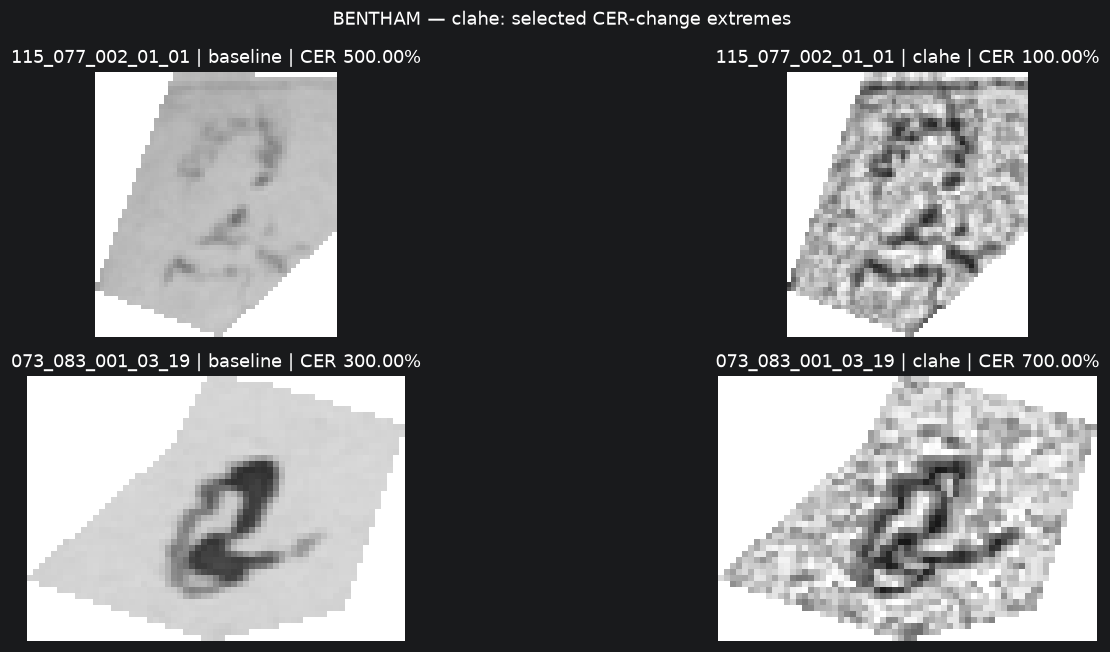

bentham/intensity_normalization/071_030_001_04_24
Reference: III 
Baseline: clack back .
Treatment: 111
bentham/intensity_normalization/071_163_004_02_01
Reference: C 
Baseline: c.
Treatment: c.i.


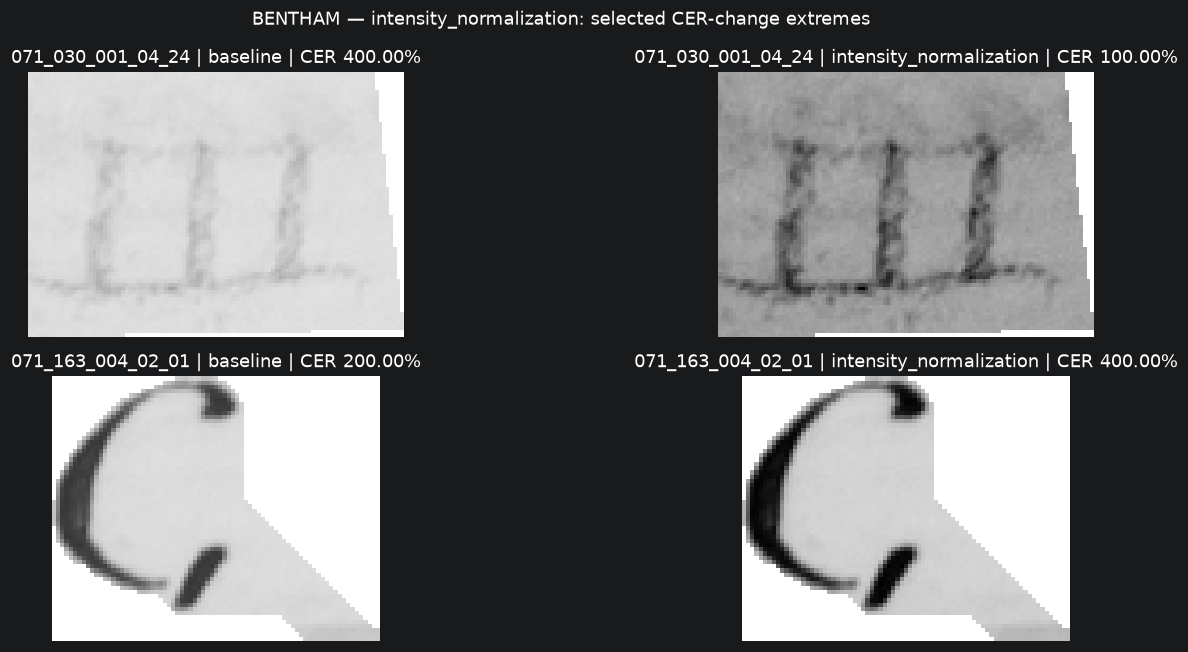

bentham/size_normalization/073_083_001_03_19
Reference: e 
Baseline: 2 .
Treatment: 2.
bentham/size_normalization/115_077_002_01_01
Reference: 9 
Baseline: ailey
Treatment: refs .


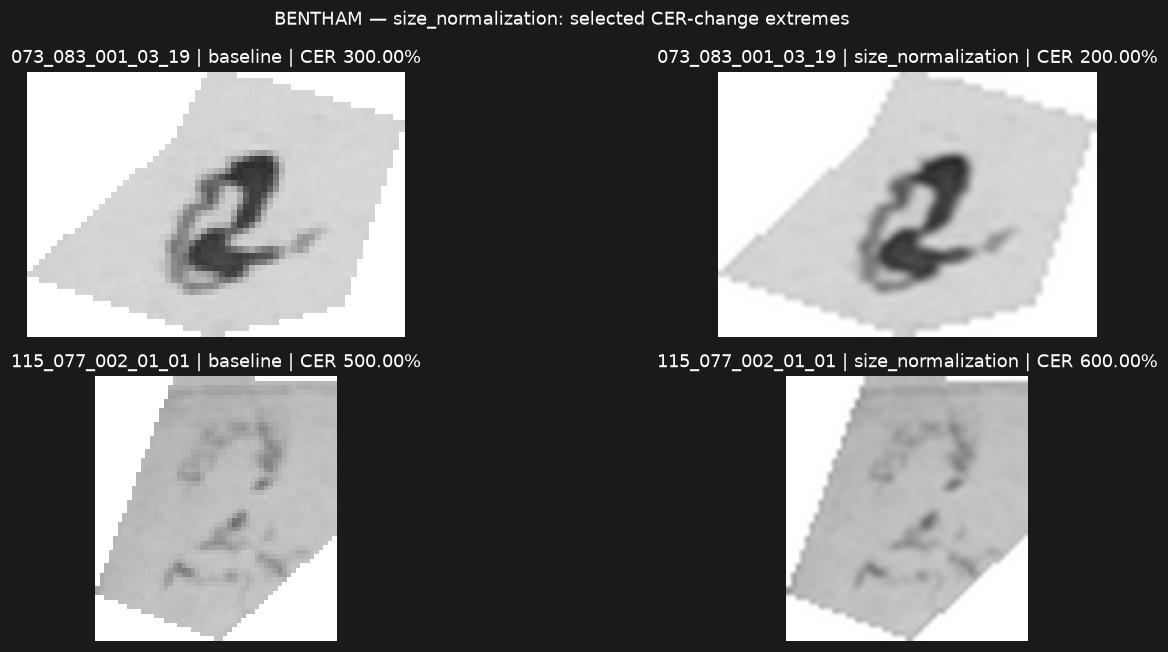

In [10]:
# Deliberately selected extremes for diagnosis, not representative examples.
for dataset_name in selected:
    paired = paired_by_dataset[dataset_name]
    sample_by_id = {s["id"]: s for s in samples_by_dataset[dataset_name]}
    lookup = predictions[predictions.dataset == dataset_name].set_index(["sample_id", "configuration"])
    for name in treatments:
        delta = paired[name] - paired["baseline"]
        example_ids = list(dict.fromkeys([delta.idxmin(), delta.idxmax()]))
        fig, axes = plt.subplots(len(example_ids), 2, figsize=(15, 3 * len(example_ids)), squeeze=False)
        for row, sample_id in enumerate(example_ids):
            sample = sample_by_id[sample_id]
            for col, config in enumerate(("baseline", name)):
                image = pipelines_by_dataset[dataset_name][config](sample["image"])
                axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=255)
                axes[row, col].set_title(f"{sample_id} | {config} | CER {100 * paired.loc[sample_id, config]:.2f}%")
                axes[row, col].axis("off")
            print(f"{dataset_name}/{name}/{sample_id}")
            print("Reference:", sample["ground_truth"])
            print("Baseline:", lookup.loc[(sample_id, "baseline"), "prediction"])
            print("Treatment:", lookup.loc[(sample_id, name), "prediction"])
        fig.suptitle(f"{dataset_name.upper()} — {name}: selected CER-change extremes")
        fig.tight_layout()
        fig.savefig(run_dir / f"{dataset_name}_examples_{name}.png", bbox_inches="tight")
        plt.show()

## Final results for IAM and Bentham

The tables below report corpus CER/WER and changes from the matching baseline for each dataset. Parameters were selected on validation and frozen before these test predictions. Treat the results as final measurements on the specified 250-line test subsets; no parameter tuning follows this evaluation.

Paired examples are diagnostic extremes, not evidence of statistical significance. IAM transcription conventions and the model's training-domain coverage affect interpretation. Deskew and optional resizing can alter the pixels seen by the mandatory model resize. Timings describe this machine and sequential run. A positive change means worse recognition; compare CER and WER separately when they disagree.

In [11]:
from src.evaluation.recognition import corpus_metrics
saved_metadata = json.loads((run_dir / "metadata.json").read_text())
assert saved_metadata["frozen_configuration_sha256"] == config_digest
assert len(predictions) == 3500
for (dataset_name, name), rows in predictions.groupby(["dataset", "configuration"], sort=False):
    assert len(rows) == 250
    measured = corpus_metrics(rows.ground_truth.tolist(), rows.prediction.tolist())
    recorded = summary[(summary.dataset == dataset_name) & (summary.configuration == name)].iloc[0]
    assert np.isclose(measured["cer"], recorded.cer, atol=1e-12, rtol=0)
    assert np.isclose(measured["wer"], recorded.wer, atol=1e-12, rtol=0)
assert outcomes[["Improved", "Unchanged", "Worsened"]].sum(axis=1).eq(250).all()
print("Frozen dataset-specific configurations selected on validation:")
display(selection_table.pivot(index="technique", columns="dataset", values="validation_configuration"))
columns = ["configuration", "sample_count", "cer_pct", "wer_pct", "cer_change_pp", "wer_change_pp"]
final_results = summary.assign(cer_pct=100 * summary.cer, wer_pct=100 * summary.wer)
for dataset_name in ("iam", "bentham"):
    print(f"{dataset_name.upper()} — FINAL TEST RESULTS ({SAMPLE_COUNT} lines)")
    display(final_results[final_results.dataset == dataset_name][columns].round(4))
both_datasets = final_results.pivot(index="configuration", columns="dataset",
    values=["cer_pct", "wer_pct"]).reindex(pipeline_names)
print("Both datasets — corpus error rates (%)")
display(both_datasets.round(4))
both_datasets.to_csv(run_dir / "final_results_both_datasets.csv")
(run_dir / "status.json").write_text(json.dumps({"status": "complete",
    "split": "test", "samples_per_dataset": 250, "completed_dataset_configuration_pairs": 14}, indent=2))
print("Results:", run_dir)

Frozen dataset-specific configurations selected on validation:


dataset,bentham,iam
technique,,
clahe,clahe_clip2_grid16x16,clahe_clip1_grid8x8
denoising,nlm_h1,nlm_h7
deskew,deskew_max10_step0.25,deskew_max5_step0.5
grayscale,grayscale,grayscale
intensity_normalization,intensity_normalization,intensity_normalization
size_normalization,size_height128,size_height128


IAM — FINAL TEST RESULTS (250 lines)


,configuration,sample_count,cer_pct,wer_pct,cer_change_pp,wer_change_pp
0,baseline,250,4.7763,10.8120,0.0000,0.0000
2,grayscale,250,4.7763,10.8120,0.0000,0.0000
4,denoising,250,4.6161,10.4980,-0.1602,-0.3140
6,deskew,250,4.7668,10.7672,-0.0094,-0.0449
8,clahe,250,4.6538,10.8569,-0.1225,0.0449
10,intensity_normalization,250,4.6350,10.8120,-0.1413,0.0000
12,size_normalization,250,4.7763,10.8120,0.0000,0.0000


BENTHAM — FINAL TEST RESULTS (250 lines)


,configuration,sample_count,cer_pct,wer_pct,cer_change_pp,wer_change_pp
1,baseline,250,16.1212,42.8855,0.0000,0.0000
3,grayscale,250,16.1212,42.8855,0.0000,0.0000
5,denoising,250,16.2375,42.5384,0.1162,-0.3471
7,deskew,250,16.9617,43.8275,0.8405,0.9420
9,clahe,250,14.7353,40.7536,-1.3859,-2.1319
11,intensity_normalization,250,15.6563,42.4888,-0.4649,-0.3966
13,size_normalization,250,16.1570,42.7863,0.0358,-0.0992


Both datasets — corpus error rates (%)


cer_pct          wer_pct         
dataset                  bentham     iam  bentham      iam
configuration                                             
baseline                 16.1212  4.7763  42.8855  10.8120
grayscale                16.1212  4.7763  42.8855  10.8120
denoising                16.2375  4.6161  42.5384  10.4980
deskew                   16.9617  4.7668  43.8275  10.7672
clahe                    14.7353  4.6538  40.7536  10.8569
intensity_normalization  15.6563  4.6350  42.4888  10.8120
size_normalization       16.1570  4.7763  42.7863  10.8120

Results: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/test/experiment_a/20261112T024202644804Z
